# 05. Parameter Optimisation, Plateau Selection & Overfitting Controls (Rounds 1–5)

With only 2–3 historical days per Prosperity round, naive parameter maximization easily mistakes finite-sample noise for structural alpha. We enforce a strict **five-gate validation pipeline** on In-Sample data before touching held-out Out-of-Sample files:
1. **2D Sensitivity Grid (`IS`)**: Evaluate unannualized tick IR (`IR_tick`) across independent-day replays under verified official position limits.
2. **Interior $3 \times 3$ Plateau Selection (`require_interior=True`)**: Maximize $\mu_{\mathcal{N}} - \lambda \sigma_{\mathcal{N}}$ over non-boundary neighborhoods.
3. **Effective Independent Trials ($N_{\text{eff}}$) & Block Deflated Sharpe Ratio (`DSR_block`)**: Evaluate 100-tick non-overlapping block Sharpes penalized for effective grid correlation $N_{\text{eff}}$.
4. **CSCV / PBO vs. White-Noise Placebo**: Compare partition rank logits across symmetric splits ($S = 8$, 70 combinations) and explain why flat correlated grids with $N_{\text{eff}} \approx 1.04$ yield neighbor-tie PBO.
5. **Single-Pass OOS & Circular Block Bootstrap**: Construct unscaled 95% confidence bounds and evaluate Round 2 Market Access Fee (MAF) arrival elasticity.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from prosperity_toolkit.analysis import OverfittingDiagnostics
from prosperity_toolkit.backtesting.engine import BacktestEngine
from prosperity_toolkit.backtesting.metrics import PerformanceMetrics
from prosperity_toolkit.backtesting.replay import build_snapshots_from_dataframes
from prosperity_toolkit.competition import (
    CompetitionStrategyAdapter,
    get_round_position_limits,
    load_competition_trader,
)
from prosperity_toolkit.data.loader import DataLoader
from prosperity_toolkit.execution.simulator import ExecutionSimulator
from prosperity_toolkit.optimisation.sensitivity import SensitivityAnalyzer

loader = DataLoader(data_root=root / "data")
limits = get_round_position_limits(1)
is_days = {
    day: build_snapshots_from_dataframes(loader.load_day_prices(1, day), loader.load_day_trades(1, day))
    for day in (-2, -1)
}
print(f"Loaded Round 1 in-sample days: { {d: len(s) for d, s in is_days.items()} } (+/-80 official limits).")

Loaded Round 1 in-sample days: {-2: 10000, -1: 10000} (+/-80 official limits).


## 1. Round 1 2D Parameter Sensitivity Surface (`min_edge` x `inventory_skew`)

Across independent IS Days `-2` and `-1`, `IR_tick` forms an interior plateau peaking cleanly at `(min_edge = 2.0, inventory_skew = 0.40)` (`local_std = 0.00009`).

In [2]:
edges = [1.5, 2.0, 2.5, 3.0, 3.5]
skews = [0.10, 0.25, 0.40, 0.55, 0.70]
ir_grid = np.zeros((len(edges), len(skews)), dtype=np.float64)
pnl_grid = np.zeros((len(edges), len(skews)), dtype=np.float64)
returns_cols = []

for i, edge in enumerate(edges):
    for j, skew in enumerate(skews):
        day_rets = []
        tot_pnl = 0.0
        for snaps in is_days.values():
            sim = ExecutionSimulator(position_limits=limits, fill_mode="queue_aware")
            trader = load_competition_trader(
                root / "traders" / "round1" / "submission.py",
                min_edge=edge,
                inventory_skew=skew,
            )
            strat = CompetitionStrategyAdapter(trader, name=f"R1(e={edge},k={skew})")
            res = BacktestEngine(simulator=sim).run(strat, snaps)
            tot_pnl += res.total_pnl
            day_rets.append(np.diff(np.asarray(res.equity_curve, dtype=np.float64), prepend=0.0))
        rets = np.concatenate(day_rets)
        ir_grid[i, j] = PerformanceMetrics.calculate_sharpe_ratio(rets.tolist(), annualization_factor=1.0)
        pnl_grid[i, j] = tot_pnl
        returns_cols.append(rets)

plateau = SensitivityAnalyzer.select_stable_plateau_2d(
    edges,
    skews,
    ir_grid,
    std_penalty=1.0,
    require_interior=True,
)
print(
    f"Selected Interior Plateau: edge={plateau.x_value}, skew={plateau.y_value} | "
    f"raw_IR={plateau.raw_score:.5f}, local_mean={plateau.local_mean:.5f}, "
    f"local_std={plateau.local_std:.5f}"
)

idx_labels = [f"edge={e:.1f}" for e in edges]
col_labels = [f"skew={s:.2f}" for s in skews]
print("In-Sample Tick Information Ratio (IR_tick):")
display(pd.DataFrame(ir_grid, index=idx_labels, columns=col_labels).round(5))
print("In-Sample Cumulative PnL (XIRECS):")
display(pd.DataFrame(pnl_grid, index=idx_labels, columns=col_labels).round(0))

Selected Interior Plateau: edge=2.0, skew=0.4 | raw_IR=0.05801, local_mean=0.05787, local_std=0.00009
In-Sample Tick Information Ratio (IR_tick):


,skew=0.10,skew=0.25,skew=0.40,skew=0.55,skew=0.70
edge=1.5,0.05668,0.05783,0.05805,0.05788,0.05774
edge=2.0,0.05685,0.05782,0.05801,0.05780,0.05775
edge=2.5,0.05692,0.05783,0.05784,0.05781,0.05777
edge=3.0,0.05696,0.05787,0.05783,0.05779,0.05772
edge=3.5,0.05702,0.05780,0.05777,0.05766,0.05751


In-Sample Cumulative PnL (XIRECS):


,skew=0.10,skew=0.25,skew=0.40,skew=0.55,skew=0.70
edge=1.5,188152.0,184690.0,183665.0,182488.0,181859.0
edge=2.0,187837.0,184556.0,183475.0,182296.0,181906.0
edge=2.5,187626.0,184254.0,183051.0,182190.0,181816.0
edge=3.0,187358.0,184135.0,182801.0,182074.0,181611.0
edge=3.5,187026.0,183861.0,182367.0,181872.0,181237.0


## 2. Effective Independent Trials ($N_{\text{eff}}$) & Block Deflated Sharpe Ratio (`DSR_block`)

Eigenvalue correlation analysis across the 25 grid cells finds $N_{\text{eff}} \approx 1.02$; evaluating 100-tick disjoint block Sharpes checks multiplicity-adjusted statistical significance without inflated sample counts.

In [3]:
mat = np.column_stack(returns_cols)
sel_idx = plateau.x_index * len(skews) + plateau.y_index
dsr, n_eff = OverfittingDiagnostics.evaluate_block_matrix_dsr(mat, sel_idx, block_size=100)
print(
    f"N_raw={mat.shape[1]}, N_eff={n_eff:.2f} | block_obs_sr={dsr.observed_sharpe:.4f}, "
    f"hurdle_sr*={dsr.expected_max_sharpe:.4f}, skew={dsr.skewness:.3f}, "
    f"ex_kurt={dsr.excess_kurtosis:.2f}, DSR_block={dsr.deflated_sharpe_ratio:.4f}"
)

trial_counts = [1, 5, 10, 25, 50, 100, 250, 500, 1000]
weak_dsrs = [
    OverfittingDiagnostics.deflated_sharpe_ratio(
        observed_sr=0.018,
        n_trials=n,
        sr_variance=0.0001,
        n_obs=mat.shape[0] // 100,
        skewness=-0.5,
        excess_kurtosis=3.0,
    ).deflated_sharpe_ratio
    for n in trial_counts
]
display(pd.DataFrame({"N_trials": trial_counts, "Weak_Signal_DSR": np.round(weak_dsrs, 4)}))

N_raw=25, N_eff=1.03 | block_obs_sr=3.9294, hurdle_sr*=0.0000, skew=-0.294, ex_kurt=1.19, DSR_block=1.0000


,N_trials,Weak_Signal_DSR
0,1,0.5998
1,5,0.5340
2,10,0.5126
3,25,0.4890
4,50,0.4733
5,100,0.4591
6,250,0.4421
7,500,0.4302
8,1000,0.4191


## 3. CSCV Probability of Backtest Overfitting (PBO) vs. Noise Control

Round 1 Grid CSCV: PBO=0.114, IS_IR=0.0582, OOS_IR=0.0581
Noise Placebo CSCV: PBO=0.671, IS_IR=0.0160, OOS_IR=-0.0025


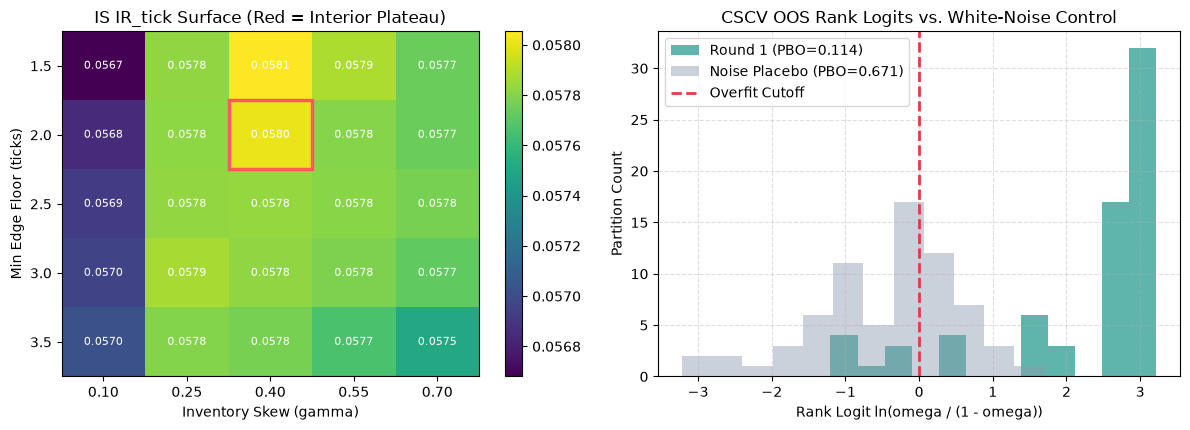

In [4]:
cscv = OverfittingDiagnostics.compute_cscv_pbo(mat, n_slices=8)
rng = np.random.default_rng(42)
noise_mat = rng.normal(0.0, 1.0, size=mat.shape)
noise_cscv = OverfittingDiagnostics.compute_cscv_pbo(noise_mat, n_slices=8)

print(
    f"Round 1 Grid CSCV: PBO={cscv.pbo:.3f}, IS_IR={cscv.mean_is_best_sharpe:.4f}, "
    f"OOS_IR={cscv.mean_oos_selected_sharpe:.4f}"
)
print(
    f"Noise Placebo CSCV: PBO={noise_cscv.pbo:.3f}, IS_IR={noise_cscv.mean_is_best_sharpe:.4f}, "
    f"OOS_IR={noise_cscv.mean_oos_selected_sharpe:.4f}"
)

fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.4))
im = axes[0].imshow(ir_grid, cmap="viridis", aspect="auto")
axes[0].set_xticks(range(len(skews)), labels=[f"{s:.2f}" for s in skews])
axes[0].set_yticks(range(len(edges)), labels=[f"{e:.1f}" for e in edges])
axes[0].set_xlabel("Inventory Skew (gamma)")
axes[0].set_ylabel("Min Edge Floor (ticks)")
axes[0].set_title("IS IR_tick Surface (Red = Interior Plateau)")
for i in range(len(edges)):
    for j in range(len(skews)):
        axes[0].text(j, i, f"{ir_grid[i, j]:.4f}", ha="center", va="center", color="white", fontsize=8)
rect = plt.Rectangle((plateau.y_index - 0.5, plateau.x_index - 0.5), 1, 1, fill=False, edgecolor="#ff595e", lw=2.5)
axes[0].add_patch(rect)
fig.colorbar(im, ax=axes[0])

axes[1].hist(cscv.logits, bins=12, alpha=0.75, color="#2a9d8f", label=f"Round 1 (PBO={cscv.pbo:.3f})")
axes[1].hist(
    noise_cscv.logits,
    bins=12,
    alpha=0.45,
    color="#8d99ae",
    label=f"Noise Placebo (PBO={noise_cscv.pbo:.3f})",
)
axes[1].axvline(0.0, color="#e63946", linestyle="--", linewidth=2.0, label="Overfit Cutoff")
axes[1].set_title("CSCV OOS Rank Logits vs. White-Noise Control")
axes[1].set_xlabel("Rank Logit ln(omega / (1 - omega))")
axes[1].set_ylabel("Partition Count")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.4)
fig.tight_layout()
plt.show()

## 4. Round 1 Single-Pass OOS (`Day 0`) & Circular Block-Bootstrap CIs

In [5]:
oos_snaps = build_snapshots_from_dataframes(loader.load_day_prices(1, 0), loader.load_day_trades(1, 0))
oos_rows = []
qa_rets = None
for mode in ("conservative", "queue_aware", "touch"):
    sim = ExecutionSimulator(position_limits=limits, fill_mode=mode)
    trader = load_competition_trader(
        root / "traders" / "round1" / "submission.py",
        min_edge=plateau.x_value,
        inventory_skew=plateau.y_value,
    )
    strat = CompetitionStrategyAdapter(trader, name="Round1Submission")
    res = BacktestEngine(simulator=sim).run(strat, oos_snaps)
    eq = np.asarray(res.equity_curve, dtype=np.float64)
    if mode == "queue_aware":
        qa_rets = np.diff(eq, prepend=0.0)
    blk_sr = PerformanceMetrics.calculate_block_sharpe(np.diff(eq, prepend=0.0).tolist(), block_size=1000)
    oos_rows.append({
        "fill_mode": mode,
        "pnl": round(res.total_pnl, 2),
        "max_dd": round(res.max_drawdown, 2),
        "ir_tick": round(res.sharpe_ratio, 5),
        "block_sharpe_1k": round(blk_sr, 3),
        "fills": len(res.fills),
    })

assert qa_rets is not None
ci = OverfittingDiagnostics.block_bootstrap_ci(
    qa_rets, block_size=100, n_bootstraps=1000, seed=42, scale_factor=1.0
)
print(
    f"Day 0 Block Bootstrap (block=100, B=1000): "
    f"IR_tick={ci.mean_sharpe:.5f} [{ci.sharpe_ci_low:.5f}, {ci.sharpe_ci_high:.5f}] | "
    f"PnL={ci.mean_total_pnl:,.1f} [{ci.pnl_ci_low:,.1f}, {ci.pnl_ci_high:,.1f}]"
)
display(pd.DataFrame(oos_rows))

Day 0 Block Bootstrap (block=100, B=1000): IR_tick=0.05458 [0.05052, 0.05875] | PnL=91,129.2 [85,711.1, 96,434.1]


,fill_mode,pnl,max_dd,ir_tick,block_sharpe_1k,fills
0,conservative,91098.0,1405.0,0.05444,9.278,712
1,queue_aware,91098.0,1405.0,0.05444,9.278,712
2,touch,91743.0,1391.0,0.05522,9.149,760


## 5. Multi-Round Plateaus, Block DSR & MAF Sensitivity (Rounds 2–5)

Below we inspect `r2_to_r5_overfitting_gates.csv`, circular block-bootstrap bounds (`scope = portfolio` vs. `asset`/`category`), and Round 2's Market Access Fee arrival elasticity. Notably, because parameter surfaces are flat and grid candidates correlate tightly ($N_{\text{eff}} \approx 1.01\text{--}1.14$), CSCV slice ranks tie easily in Rounds 2 and 5 (`PBO = 0.300` / `0.543`), whereas every round clears `DSR_block >= 0.978` across independent 100-tick blocks prior to OOS deployment.

,round,plateau_params,is_ir_tick,local_mean,local_std,n_eff,cscv_pbo,dsr_block,oos_pnl,oos_ir_tick,oos_block_sharpe_1k
0,2,"edge=2.5,skew=0.4",0.060523,0.060408,0.000107,1.0401,0.3000,1.0000,94209.0,0.054659,8.2366
1,3,"spot_scale=30.0,enter_band=10.0",0.015932,0.015827,0.000606,1.0109,0.0000,0.9966,95093.0,0.005840,0.5730
2,4,"spot_scale=30.0,flow_weight=1.5",0.011374,0.011353,0.000448,1.0157,0.0143,0.9783,260540.0,0.016796,0.6461
3,5,"vsm=0.18,ef=0.14,mc=0.16",0.033978,0.034599,0.000551,1.1437,0.5429,1.0000,97628.0,0.026240,1.1075


,arrival_rate,mean_pnl,std_pnl,median_pnl,var_95,cvar_95,prob_loss,prob_loss_ci95_upper,mean_ir_tick
0,0.04,6696.18,2924.51,5913.00,2536.72,1931.00,0.0,0.0876,0.0478
1,0.06,8834.42,3323.74,8360.75,3718.12,2308.75,0.0,0.0876,0.0626
2,0.08,10966.54,3082.91,10783.75,6556.43,4548.00,0.0,0.0876,0.0764
3,0.10,12631.66,2982.79,13274.50,6491.52,5525.75,0.0,0.0876,0.0893
4,0.12,13140.95,3036.35,13006.00,8734.33,8266.75,0.0,0.0876,0.0938


,round,scope,bucket,oos_pnl,boot_ir_tick_lo,boot_ir_tick_hi,boot_pnl_lo,boot_pnl_hi
0,2,portfolio,PORTFOLIO,94209.0,0.050891,0.058413,87698.94,100093.15
1,2,asset,ASH_COATED_OSMIUM,13046.0,NaN,NaN,NaN,NaN
2,2,asset,INTARIAN_PEPPER_ROOT,81163.0,NaN,NaN,NaN,NaN
3,3,portfolio,PORTFOLIO,95093.0,-0.011181,0.021327,-184416.62,355675.89
4,3,asset,HYDROGEL_PACK,23078.0,NaN,NaN,NaN,NaN
5,3,asset,VELVETFRUIT_EXTRACT,10866.0,NaN,NaN,NaN,NaN
6,3,asset,VEV_4000,6239.0,NaN,NaN,NaN,NaN
7,3,asset,VEV_4500,6188.0,NaN,NaN,NaN,NaN
8,3,asset,VEV_5000,13790.0,NaN,NaN,NaN,NaN
9,3,asset,VEV_5100,12814.0,NaN,NaN,NaN,NaN


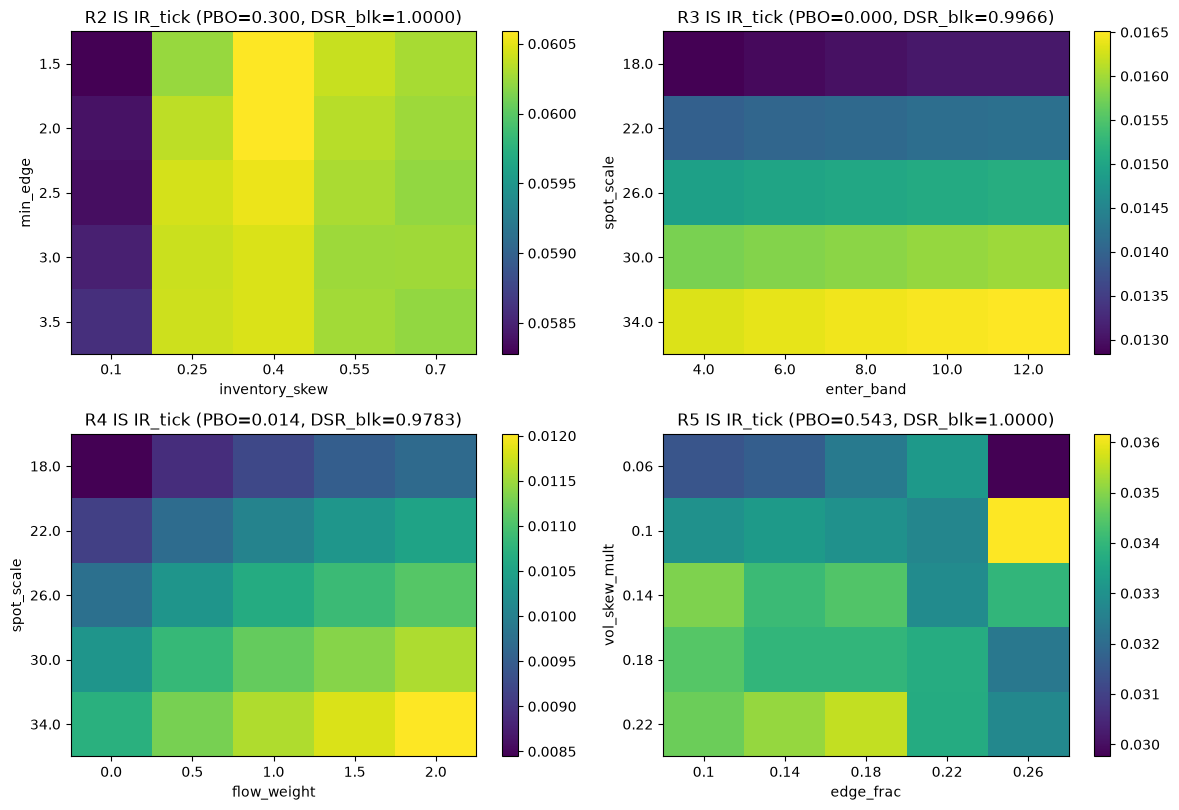

In [6]:
gates_df = pd.read_csv(root / "reports" / "tables" / "r2_to_r5_overfitting_gates.csv")
display(gates_df)

maf_df = pd.read_csv(root / "reports" / "tables" / "r2_maf_sensitivity.csv")
display(maf_df)

boot_df = pd.read_csv(root / "reports" / "tables" / "r2_to_r5_bootstrap_and_attribution.csv")
display(boot_df)

pbo_map = {int(r["round"]): float(r["cscv_pbo"]) for _, r in gates_df.iterrows()}
dsr_map = {int(r["round"]): float(r["dsr_block"]) for _, r in gates_df.iterrows()}
fig, axes = plt.subplots(2, 2, figsize=(12.0, 8.2))
grid_specs = [
    (2, "r2_sensitivity_grid.csv", "inventory_skew", "min_edge", "R2 IS IR_tick"),
    (3, "r3_sensitivity_grid.csv", "enter_band", "spot_scale", "R3 IS IR_tick"),
    (4, "r4_sensitivity_grid.csv", "flow_weight", "spot_scale", "R4 IS IR_tick"),
    (5, "r5_sensitivity_grid.csv", "edge_frac", "vol_skew_mult", "R5 IS IR_tick"),
]
for idx, (rnum, fname, xcol, ycol, prefix) in enumerate(grid_specs):
    ax = axes[idx // 2, idx % 2]
    gdf = pd.read_csv(root / "reports" / "tables" / fname)
    piv = gdf.pivot(index=ycol, columns=xcol, values="is_ir_tick")
    im = ax.imshow(piv.to_numpy(), cmap="viridis", aspect="auto")
    ax.set_xticks(range(len(piv.columns)), labels=[f"{v}" for v in piv.columns])
    ax.set_yticks(range(len(piv.index)), labels=[f"{v}" for v in piv.index])
    ax.set_xlabel(xcol)
    ax.set_ylabel(ycol)
    ax.set_title(
        f"{prefix} (PBO={pbo_map.get(rnum, float('nan')):.3f}, "
        f"DSR_blk={dsr_map.get(rnum, float('nan')):.4f})"
    )
    fig.colorbar(im, ax=ax)
fig.tight_layout()
plt.show()